# 01 – Data Overview

In this notebook I set up the project and check that all libraries work.

In [1]:
import pandas as pd
pd.__version__

'3.1.1'

In [9]:
df = pd.read_csv("../data/raw/nintendo_lifetime_sales.csv")

df

,platform,hardware_million,software_million
0,Switch 2,26.35,73.21
1,Switch,157.20,1593.87
2,Wii U,13.56,103.60
3,Wii,101.63,921.85


In [11]:
df.shape

(4, 3)

In [12]:
df.columns

Index(['platform', 'hardware_million', 'software_million'], dtype='str')

In [13]:
df.dtypes

platform                str
hardware_million    float64
software_million    float64
dtype: object

In [14]:
df.describe()

,hardware_million,software_million
count,4.000000,4.000000
mean,74.685000,673.132500
std,67.348091,728.901505
min,13.560000,73.210000
25%,23.152500,96.002500
50%,63.990000,512.725000
75%,115.522500,1089.855000
max,157.200000,1593.870000


In [15]:
df.sort_values(by="hardware_million")

,platform,hardware_million,software_million
2,Wii U,13.56,103.60
0,Switch 2,26.35,73.21
3,Wii,101.63,921.85
1,Switch,157.20,1593.87


In [17]:
df.sort_values(by="hardware_million", ascending=False)

,platform,hardware_million,software_million
1,Switch,157.20,1593.87
3,Wii,101.63,921.85
0,Switch 2,26.35,73.21
2,Wii U,13.56,103.60


In [18]:
df[["platform", "hardware_million"]]

,platform,hardware_million
0,Switch 2,26.35
1,Switch,157.20
2,Wii U,13.56
3,Wii,101.63


In [19]:
df[df["hardware_million"] > 50]

,platform,hardware_million,software_million
1,Switch,157.20,1593.87
3,Wii,101.63,921.85


In [20]:
df[df["hardware_million"] >= 100]

,platform,hardware_million,software_million
1,Switch,157.20,1593.87
3,Wii,101.63,921.85


In [21]:
df[
    (df["hardware_million"] > 10) &
    (df["software_million"] > 100)
]

,platform,hardware_million,software_million
1,Switch,157.20,1593.87
2,Wii U,13.56,103.60
3,Wii,101.63,921.85


In [22]:
df[
    (df["hardware_million"] > 100) |
    (df["software_million"] > 1000)
]

,platform,hardware_million,software_million
1,Switch,157.20,1593.87
3,Wii,101.63,921.85


In [23]:
df[
    (df["hardware_million"] < 30) &
    (df["software_million"] > 100)
]

,platform,hardware_million,software_million
2,Wii U,13.56,103.6


In [24]:
df.isnull().sum()

platform            0
hardware_million    0
software_million    0
dtype: int64

In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df["platform"].nunique()

4

In [27]:
df["platform"].unique()

<StringArray>
['Switch 2', 'Switch', 'Wii U', 'Wii']
Length: 4, dtype: str

In [28]:
df.groupby("platform")["hardware_million"].sum()

platform
Switch      157.20
Switch 2     26.35
Wii         101.63
Wii U        13.56
Name: hardware_million, dtype: float64

In [29]:
df["hardware_million"].mean()

np.float64(74.685)

In [30]:
df.groupby("platform")["hardware_million"].mean()

platform
Switch      157.20
Switch 2     26.35
Wii         101.63
Wii U        13.56
Name: hardware_million, dtype: float64

In [31]:
df.groupby("platform")["hardware_million"].agg(["sum", "mean", "max"])

,sum,mean,max
platform,,,
Switch,157.20,157.20,157.20
Switch 2,26.35,26.35,26.35
Wii,101.63,101.63,101.63
Wii U,13.56,13.56,13.56


In [32]:
df[["platform", "hardware_million", "software_million"]]

,platform,hardware_million,software_million
0,Switch 2,26.35,73.21
1,Switch,157.20,1593.87
2,Wii U,13.56,103.60
3,Wii,101.63,921.85


In [33]:
df["software_hardware_ratio"] = (
    df["software_million"] / df["hardware_million"]
)

df


,platform,hardware_million,software_million,software_hardware_ratio
0,Switch 2,26.35,73.21,2.778368
1,Switch,157.20,1593.87,10.139122
2,Wii U,13.56,103.60,7.640118
3,Wii,101.63,921.85,9.070648


In [34]:
df["software_hardware_ratio"] = df["software_hardware_ratio"].round(2)

df

,platform,hardware_million,software_million,software_hardware_ratio
0,Switch 2,26.35,73.21,2.78
1,Switch,157.20,1593.87,10.14
2,Wii U,13.56,103.60,7.64
3,Wii,101.63,921.85,9.07


In [35]:
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


In [36]:
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

<BarContainer object of 4 artists>

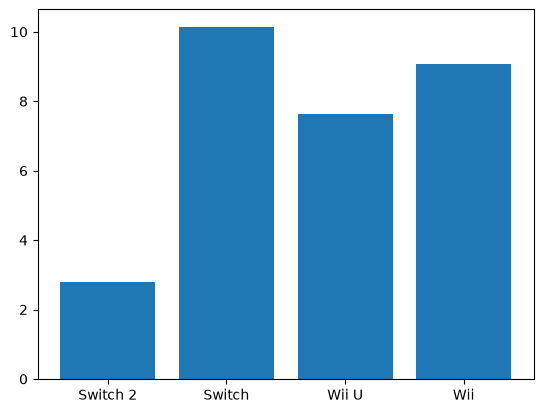

In [37]:
plt.bar(df["platform"], df["software_hardware_ratio"])

Text(0, 0.5, 'Software-to-Hardware Ratio')

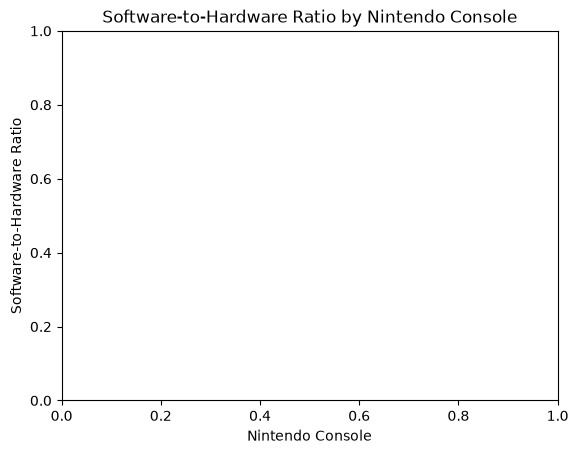

In [38]:
plt.title("Software-to-Hardware Ratio by Nintendo Console")
plt.xlabel("Nintendo Console")
plt.ylabel("Software-to-Hardware Ratio")

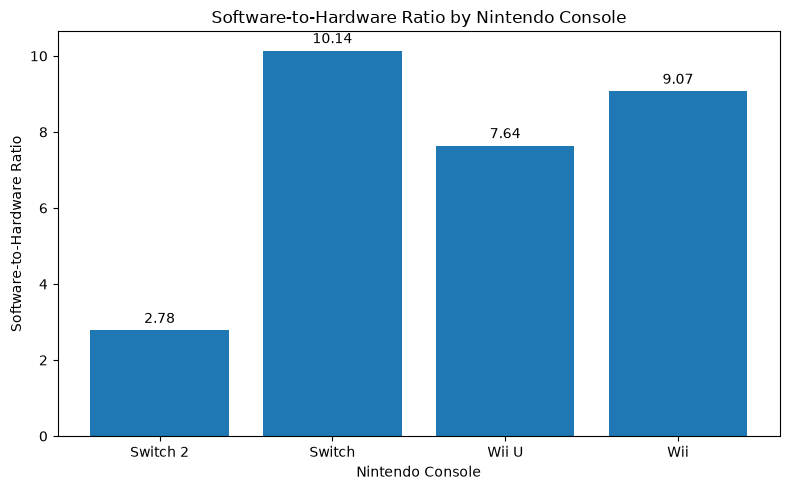

In [40]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    df["platform"],
    df["software_hardware_ratio"]
)

plt.title("Software-to-Hardware Ratio by Nintendo Console")
plt.xlabel("Nintendo Console")
plt.ylabel("Software-to-Hardware Ratio")

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()
plt.show()

In [41]:
plt.savefig("../reports/figures/software_hardware_ratio.png", dpi=300)

<Figure size 640x480 with 0 Axes>

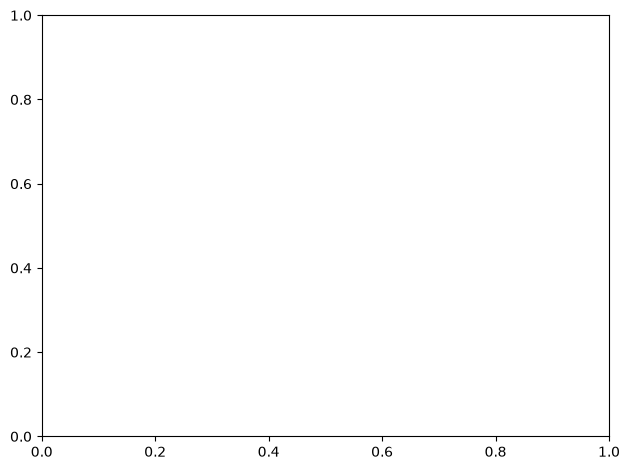

In [43]:
plt.bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("../reports/figures/software_hardware_ratio.png", dpi=300)
plt.show()

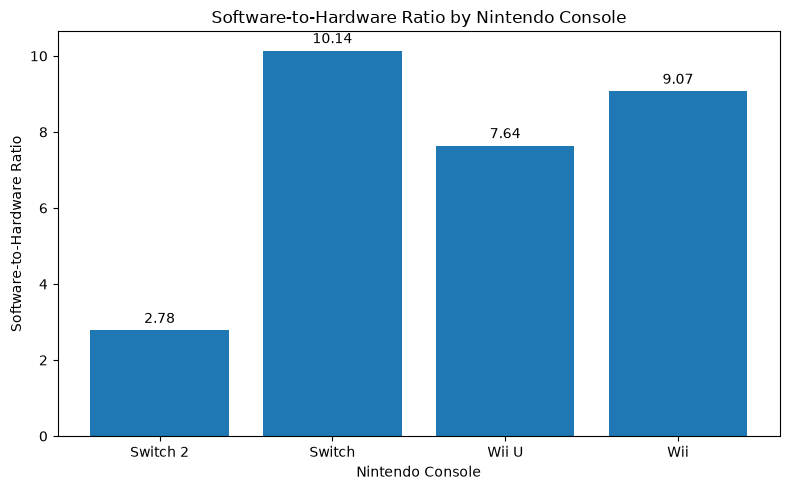

In [44]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    df["platform"],
    df["software_hardware_ratio"]
)

plt.title("Software-to-Hardware Ratio by Nintendo Console")
plt.xlabel("Nintendo Console")
plt.ylabel("Software-to-Hardware Ratio")

plt.bar_label(bars, fmt="%.2f", padding=3)

plt.tight_layout()
plt.savefig("../reports/figures/software_hardware_ratio.png", dpi=300)
plt.show()

**Interpretation:**

The Switch has the highest ratio with 10.14 games per console.
The Switch 2 has the lowest ratio with 2.78.
However, the Switch 2 has only been on the market since June 2025,
while the Switch has been on the market since March 2017.
Because the numbers are life-to-date, the consoles are not directly comparable.